# Fit one flight

Calibrate the camera from `trajectories/game1_landmarks.yaml`, check the court, then fit one ballistic flight. Shot and bounce cuts use the smoothed court-plane track, with the same thresholds as `shots.ipynb`. Change `FLIGHT_INDEX` to fit a different flight from the list.

The net-post landmarks are the tops of the posts. The green posts should meet those marks. A camera under the court draws the posts downward, with the projected tops sitting on the court line.

When the flight ends on a bounce, the fit also uses the tracked flight from that bounce to the next hit. The two share the bounce position. The ball is on the ground. Vertical velocity on the way up is fit to those frames, and the horizontal velocity is kept aside from a slowdown.


In [ ]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import mpl_toolkits.mplot3d  # noqa: F401
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
from tracking.efficient.model import EfficientTracker
from trajectories.ballistic import FPS, ballistic, fit_flight, fit_shot, simulate
from tracking.ssm.base_akf.model import rts_smooth
from trajectories.camera import (
    court_from_image,
    draw_court,
    estimate_camera,
    estimate_homography,
    reprojection_rmse,
    validate_court,
)
from trajectories.court import load_landmarks, marked, segments
from trajectories.segment import detect_cuts, iter_flights, select_flight

LANDMARKS = ROOT / "trajectories" / "game1_landmarks.yaml"
with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    dataset = (ROOT / dataset).resolve()


In [2]:
landmarks, meta = load_landmarks(LANDMARKS)
ready = marked(landmarks)
ground = [item for item in ready if abs(float(item.world[2])) <= 1e-8]
if meta["frame"] is None or len(ground) < 4:
    raise RuntimeError(
        "Fill frame and at least 4 ground-point image pixels in "
        "trajectories/game1_landmarks.yaml. "
        f"frame={meta['frame']!r}, marked ground points={len(ground)}."
    )
if (SRC_W, SRC_H) != tuple(meta["image_size"]):
    raise RuntimeError(
        f"landmark image_size {meta['image_size']} does not match the tracker "
        f"{SRC_W}x{SRC_H}"
    )
width, height = meta["image_size"]
frame_path = dataset / meta["frame"]
print(f"{meta['frame']}  {len(ready)} landmarks, {len(ground)} on the ground")


game1/Clip1/0001.jpg  18 landmarks, 16 on the ground


## Camera

The homography maps the ground plane. The pinhole camera is what puts the ball, which is off the ground, back into the image. Net posts, when marked, refine the focal length. The printed center should be above the court, so its Z is positive.


focal 1828 px  center [ 0.09 32.69  8.52] m  landmark reprojection 1.92 px
  doubles_near_left        2.30 px   marked (  190.0,  535.0)   projected (  191.8,  533.6)
  doubles_near_right       2.37 px   marked ( 1090.0,  530.0)   projected ( 1087.9,  531.0)
  doubles_far_left         1.66 px   marked (  420.0,  165.0)   projected (  420.0,  166.7)
  doubles_far_right        0.62 px   marked (  865.0,  165.0)   projected (  864.4,  165.1)
  singles_near_left        2.22 px   marked (  305.0,  535.0)   projected (  303.6,  533.3)
  singles_near_right       1.57 px   marked (  975.0,  530.0)   projected (  975.8,  531.4)
  singles_far_left         1.53 px   marked (  475.0,  165.0)   projected (  475.4,  166.5)
  singles_far_right        1.19 px   marked (  810.0,  165.0)   projected (  808.8,  165.3)
  service_near_left        1.67 px   marked (  370.0,  395.0)   projected (  368.3,  395.1)
  service_near_right       3.30 px   marked (  910.0,  395.0)   projected (  912.9,  393.4)
  ser

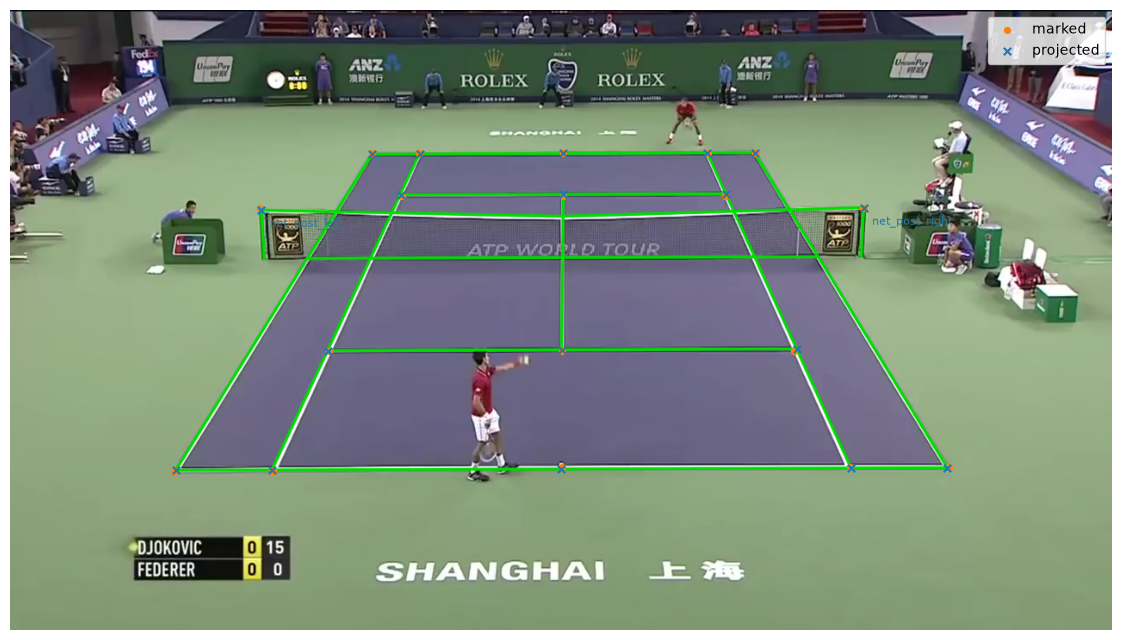

In [3]:
bgr = cv2.imread(str(frame_path), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(frame_path)
if bgr.shape[1] != width or bgr.shape[0] != height:
    raise RuntimeError(
        f"{frame_path.name} is {bgr.shape[1]}x{bgr.shape[0]}, "
        f"landmarks are marked for {width}x{height}"
    )

world = np.stack([item.world for item in ready])
uv = np.stack([item.image for item in ready])
on_ground = np.abs(world[:, 2]) <= 1e-8
H = estimate_homography(world[on_ground, :2], uv[on_ground])
camera = estimate_camera(world, uv, (width, height), homography=H)
center = camera.center()
print(
    f"focal {camera.focal:.0f} px  "
    f"center {np.array2string(center, precision=2)} m  "
    f"landmark reprojection {reprojection_rmse(camera, world, uv):.2f} px"
)
if center[2] <= 0.5:
    print("camera is under the court; the net posts will project downward")

overlay = draw_court(bgr, camera)
projected = camera.project(world)
error = np.linalg.norm(projected - uv, axis=1)
for item, err, pred in zip(ready, error, projected):
    print(
        f"  {item.name:22} {err:6.2f} px"
        f"   marked ({item.image[0]:7.1f}, {item.image[1]:6.1f})"
        f"   projected ({pred[0]:7.1f}, {pred[1]:6.1f})"
    )

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
ax.scatter(uv[:, 0], uv[:, 1], s=18, c="C1", label="marked")
ax.scatter(projected[:, 0], projected[:, 1], s=28, marker="x", c="C0", label="projected")
for item, pred in zip(ready, projected):
    if item.name.startswith("net_"):
        ax.annotate(
            item.name,
            pred,
            color="C0",
            fontsize=8,
            xytext=(6, -12),
            textcoords="offset points",
        )
ax.legend(loc="upper right")
ax.set_axis_off()
fig.tight_layout()
plt.show()


## Court check

Ground points are mapped back onto the court. This raises, and the cells below do not run, when the RMS error is above 20 cm or a measured length is off by more than 3%.


In [4]:
report = validate_court(ready, H)
print(report)


court RMS 0.115 m
  doubles_near_left: 0.024 m
  doubles_near_right: 0.039 m
  doubles_far_left: 0.205 m
  doubles_far_right: 0.057 m
  singles_near_left: 0.043 m
  singles_near_right: 0.030 m
  singles_far_left: 0.188 m
  singles_far_right: 0.078 m
  service_near_left: 0.025 m
  service_near_right: 0.101 m
  service_far_left: 0.115 m
  service_far_right: 0.216 m
  baseline_near: 0.077 m
  baseline_far: 0.129 m
  service_near: 0.038 m
  service_far: 0.160 m
  baseline length: 23.886 m (expected 23.77 m)
  doubles width: 11.019 m (expected 10.97 m)
  service depth: 6.337 m (expected 6.40 m)


## Track

The clip that contains the calibration frame. Shots and bounces use the filtered track. The fit uses the measurements.


In [5]:
rel = Path(meta["frame"])
game, clip = rel.parts[0], rel.parts[1]


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = dataset / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "status": int(row["status"] or 0),
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def read_bgr(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)
    if image.shape[1] != width or image.shape[0] != height:
        image = cv2.resize(image, (width, height), interpolation=cv2.INTER_AREA)
    return image


tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
tracker.rules.start_at_uncertainty = True

frames = load_clip(game, clip)
grays = [read_gray(frame["path"]) for frame in frames]
rgbs = [read_rgb(frame["path"]) for frame in frames]
steps = tracker.find_positions(grays, rgbs)

n = len(frames)
post = np.full((n, 2), np.nan)
meas = np.full((n, 2), np.nan)
r_std = np.full(n, np.nan)
state = np.full((n, 4), np.nan)
cov = np.zeros((n, 4, 4))
pred_state = np.full((n, 4), np.nan)
pred_cov = np.zeros((n, 4, 4))
status = np.array([frame["status"] for frame in frames], dtype=np.int64)
for i, step in enumerate(steps):
    if step is None:
        continue
    post[i] = step["post"]
    state[i] = step["state"]
    cov[i] = step["cov"]
    if step["pred_state"] is not None:
        pred_state[i] = step["pred_state"]
        pred_cov[i] = step["pred_cov"]
    if step["used"] and step["z"] is not None:
        meas[i] = step["z"]
        r_std[i] = step["r_std"]
print(
    f"{game}/{clip}  {n} frames  "
    f"measured {int(np.isfinite(meas).all(axis=1).sum())}"
)


game1/Clip1  207 frames  measured 184


## Which flight

Cuts use the smoothed track mapped onto the court, with the same thresholds as `shots.ipynb`. `None` uses the flight `select_flight` prefers: one that ends on a bounce, otherwise the one with the most measurements. Set `FLIGHT_INDEX` to a row from the list. `BOUNCE_START` and `BOUNCE_END` override the bounce constraint on the fit. `None` follows the cut.

Selecting either the shot or the bounce-to-hit flight fits the pair, so the bounce state is the same on both sides.


In [7]:
EVENT_MPS = 10.0
HIT_Y_CHANGE_MPS = 50
BOUNCE_Y_CHANGE_MPS = 8.0
X_CHANGE_MPS = 10.0
REQUIRE_Y_FLIP = False
X_ZERO_FRAMES = 4
X_ZERO_MPS = 0.0
WINDOW = 5
REARM_MPS = 6.0
MIN_GAP = 5
FLIGHT_INDEX = None
BOUNCE_START = None
BOUNCE_END = None

smooth_xy = rts_smooth(state, cov, pred_state, pred_cov)[:, :2]
court = court_from_image(smooth_xy, H)
event_change = EVENT_MPS / FPS
hit_y_change = HIT_Y_CHANGE_MPS / FPS
bounce_y_change = BOUNCE_Y_CHANGE_MPS / FPS
x_change = X_CHANGE_MPS / FPS
rearm_change = REARM_MPS / FPS
shots, bounces = detect_cuts(
    court,
    status,
    event_change=event_change,
    hit_y_change=hit_y_change,
    bounce_y_change=bounce_y_change,
    x_change=x_change,
    require_y_flip=REQUIRE_Y_FLIP,
    x_zero_frames=X_ZERO_FRAMES,
    x_zero=X_ZERO_MPS / FPS,
    window=WINDOW,
    rearm=rearm_change,
    min_gap=MIN_GAP,
)
flights = iter_flights(n, shots, bounces)
for i, item in enumerate(flights):
    segment = meas[item.start : item.end + 1]
    count = int(np.isfinite(segment).all(axis=1).sum())
    print(
        f"{i:2d}  {frames[item.start]['file']} → {frames[item.end]['file']}"
        f"  measured {count:3d}  ends on bounce: {item.ends_on_bounce}"
    )

if FLIGHT_INDEX is None:
    flight = select_flight(meas, shots, bounces)
    chosen = next(
        i
        for i, item in enumerate(flights)
        if item.start == flight.start and item.end == flight.end
    )
else:
    chosen = int(FLIGHT_INDEX)
    flight = flights[chosen]
print(
    f"flight {chosen}  {frames[flight.start]['file']} → {frames[flight.end]['file']}  "
    f"ends on bounce: {flight.ends_on_bounce}"
)


 0  0000.jpg → 0025.jpg  measured  24  ends on bounce: False
 1  0026.jpg → 0033.jpg  measured   8  ends on bounce: True
 2  0033.jpg → 0040.jpg  measured   8  ends on bounce: False
 3  0041.jpg → 0074.jpg  measured  30  ends on bounce: True
 4  0074.jpg → 0083.jpg  measured   0  ends on bounce: False
 5  0084.jpg → 0105.jpg  measured  22  ends on bounce: True
 6  0105.jpg → 0114.jpg  measured   8  ends on bounce: False
 7  0115.jpg → 0131.jpg  measured  16  ends on bounce: True
 8  0131.jpg → 0140.jpg  measured  10  ends on bounce: False
 9  0141.jpg → 0164.jpg  measured  23  ends on bounce: True
10  0164.jpg → 0173.jpg  measured  10  ends on bounce: False
11  0174.jpg → 0191.jpg  measured  15  ends on bounce: True
12  0191.jpg → 0206.jpg  measured  15  ends on bounce: False
flight 3  0041.jpg → 0074.jpg  ends on bounce: True


## Fit

The six parameters are the position and velocity at the first frame of the shot. Gravity is the only acceleration. Each detection is weighted by the tracker's measurement std.

A shot that ends on a bounce is on the ground there. The flight from the bounce to the next hit starts at that position. Vertical velocity on the way up is fit to those frames, and the horizontal velocity is kept aside from a slowdown. `BOUNCE_END = False` leaves this off and fits the selected flight on its own.


In [ ]:
idx = np.arange(flight.start, flight.end + 1)
keep = np.isfinite(meas[idx]).all(axis=1)
idx = idx[keep]
uv_obs = meas[idx]
t = (idx - flight.start) / FPS
weights = r_std[idx]
bounce_frames = {int(i) for i in bounces}
shot_frames = {int(i) for i in shots}


def continuation(shot):
    return next(
        (
            item
            for item in flights
            if item.start == shot.end and item.end > shot.end and not item.ends_on_bounce
        ),
        None,
    )


def shot_before(item):
    return next(
        (earlier for earlier in flights if earlier.ends_on_bounce and earlier.end == item.start),
        None,
    )


def measured(item, origin):
    ids = np.arange(item.start, item.end + 1)
    ids = ids[np.isfinite(meas[ids]).all(axis=1)]
    return ids, meas[ids], (ids - origin) / FPS, r_std[ids]


starts_on_bounce = flight.start in bounce_frames and flight.start not in shot_frames
if flight.ends_on_bounce and BOUNCE_END is not False:
    shot_flight = flight
elif starts_on_bounce and BOUNCE_END is not False:
    shot_flight = shot_before(flight)
else:
    shot_flight = None

follow_flight = None
follow_idx = np.empty(0, dtype=int)
follow_uv = np.empty((0, 2))
follow_t = np.empty(0)
shot_idx = idx
shot_uv = uv_obs
shot_t = t
t_bounce = float(t[-1]) if len(t) else 0.0
linked = False

if shot_flight is not None:
    shot_idx, shot_uv, shot_t, shot_w = measured(shot_flight, shot_flight.start)
    if len(shot_idx) >= 4:
        linked = True
        t_bounce = (shot_flight.end - shot_flight.start) / FPS
        kwargs = {"t_bounce": t_bounce}
        follow_flight = continuation(shot_flight)
        if follow_flight is not None:
            follow_idx, follow_uv, follow_t, follow_w = measured(follow_flight, follow_flight.start)
            if len(follow_idx) >= 2:
                kwargs.update(
                    follow_uv=follow_uv,
                    follow_t=follow_t,
                    follow_weights=follow_w,
                )
            else:
                follow_flight = None
                follow_idx = np.empty(0, dtype=int)
        print(
            f"shot {frames[shot_flight.start]['file']} → {frames[shot_flight.end]['file']}"
            f"   samples {len(shot_idx)}"
        )
        if follow_flight is not None:
            print(
                f"bounce to hit {frames[follow_flight.start]['file']} → {frames[follow_flight.end]['file']}"
                f"   samples {len(follow_idx)}"
            )
        else:
            print("bounce to hit   no measurements")
        fit = fit_shot(shot_uv, shot_t, camera, H, shot_w, **kwargs)

if not linked:
    bounce_start = int(idx[0]) in bounce_frames if BOUNCE_START is None else bool(BOUNCE_START)
    bounce_end = (
        flight.ends_on_bounce and int(idx[-1]) == flight.end
        if BOUNCE_END is None
        else bool(BOUNCE_END)
    )
    print(f"bounce start {bounce_start}   bounce end {bounce_end}   samples {len(idx)}")
    fit = fit_flight(
        uv_obs,
        t,
        camera,
        H,
        weights,
        bounce_end=bounce_end,
        bounce_start=bounce_start,
    )
    shot_flight = flight
    shot_idx, shot_uv, shot_t = idx, uv_obs, t
    t_bounce = float(t[-1])
    follow_flight = None

names = ["X0", "Y0", "Z0", "vx0", "vy0", "vz0"]
units = ["m", "m", "m", "m/s", "m/s", "m/s"]
print(
    "shot  "
    + "  ".join(f"{name}={value:7.2f} {unit}" for name, value, unit in zip(names, fit.theta, units))
)
if fit.follow_theta is not None:
    bounce_pos, bounce_vel = simulate(fit.theta, np.array([t_bounce]))
    outgoing = fit.follow_theta
    print(
        f"bounce  X={bounce_pos[0, 0]:7.2f} m  Y={bounce_pos[0, 1]:7.2f} m  Z={bounce_pos[0, 2]:7.2f} m"
    )
    print(
        "in    "
        + "  ".join(
            f"{name}={value:7.2f} m/s" for name, value in zip(["vx", "vy", "vz"], bounce_vel[0])
        )
    )
    print(
        "out   "
        + "  ".join(f"{name}={value:7.2f} m/s" for name, value in zip(["vx", "vy", "vz"], outgoing[3:]))
    )
print(f"pixel RMSE {fit.rmse_px:.2f}  {fit.message}")
if fit.follow_rmse_px is not None:
    print(f"bounce to hit RMSE {fit.follow_rmse_px:.2f}")


## Check the flight

The curves are the fitted ball in court coordinates. Blue is the shot. Green is the flight from the bounce to the next hit, and it starts from the bounce state above. Projecting a curve back into the clip should land on the detections. `+Y` points toward the near baseline, the same way as pixel y, and `+Z` is up.


In [ ]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
for start, end in segments():
    ax.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        [start[2], end[2]],
        color="0.6",
        lw=0.8,
    )
shot_curve = ballistic(fit.theta, np.linspace(float(shot_t[0]), float(t_bounce), 80))
ax.plot(shot_curve[:, 0], shot_curve[:, 1], shot_curve[:, 2], color="C0", lw=2, label="shot")
ax.scatter(fit.xyz[:, 0], fit.xyz[:, 1], fit.xyz[:, 2], s=12, c="C0")
if fit.follow_theta is not None and len(follow_t):
    follow_curve = ballistic(fit.follow_theta, np.linspace(0.0, float(follow_t[-1]), 40))
    ax.plot(
        follow_curve[:, 0],
        follow_curve[:, 1],
        follow_curve[:, 2],
        color="C2",
        lw=2,
        label="bounce to hit",
    )
    ax.scatter(fit.follow_xyz[:, 0], fit.follow_xyz[:, 1], fit.follow_xyz[:, 2], s=12, c="C2")
    ax.legend(loc="upper right")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.set_box_aspect((23.77, 10.97, 6.0))
end_name = frames[follow_flight.end]["file"] if follow_flight is not None else frames[shot_flight.end]["file"]
ax.set_title(f"{frames[shot_flight.start]['file']} → {end_name}")
fig.tight_layout()
plt.show()


In [ ]:
def curve_uv(theta, t0, t1, count=60):
    times = np.linspace(float(t0), float(t1), count)
    return camera.project(ballistic(theta, times))


shot_pred = curve_uv(fit.theta, shot_t[0], t_bounce)
follow_pred = None
if fit.follow_theta is not None and len(follow_t):
    follow_pred = curve_uv(fit.follow_theta, 0.0, follow_t[-1])

shot_err = np.linalg.norm(fit.uv_hat - shot_uv, axis=1)
print(
    f"shot predicted vs detected  n={len(shot_err)}  "
    f"RMSE {np.sqrt(np.mean(shot_err**2)):.2f} px  max {shot_err.max():.2f} px"
)
if follow_pred is not None:
    follow_err = np.linalg.norm(fit.follow_uv_hat - follow_uv, axis=1)
    print(
        f"bounce to hit predicted vs detected  n={len(follow_err)}  "
        f"RMSE {np.sqrt(np.mean(follow_err**2)):.2f} px  max {follow_err.max():.2f} px"
    )

show = [int(shot_idx[0]), int(shot_idx[len(shot_idx) // 2]), int(shot_idx[-1])]
if follow_flight is not None and len(follow_idx):
    show = [int(shot_idx[0]), int(shot_idx[-1]), int(follow_idx[-1])]
seen = []
for frame_i in show:
    if frame_i not in seen:
        seen.append(frame_i)
show = seen

shot_order = {int(frame_i): k for k, frame_i in enumerate(shot_idx)}
follow_order = {int(frame_i): k for k, frame_i in enumerate(follow_idx)}
fig, axes = plt.subplots(1, len(show), figsize=(4.6 * len(show), 4))
axes = np.atleast_1d(axes)
for ax, frame_i in zip(axes, show):
    image = cv2.cvtColor(read_bgr(frames[frame_i]["path"]), cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.plot(shot_pred[:, 0], shot_pred[:, 1], color="C0", lw=1, label="shot")
    if follow_pred is not None:
        ax.plot(follow_pred[:, 0], follow_pred[:, 1], color="C2", lw=1, label="bounce to hit")
    if frame_i in shot_order:
        k = shot_order[frame_i]
        ax.scatter(shot_uv[k, 0], shot_uv[k, 1], c="C1", s=30, label="detected")
        ax.scatter(fit.uv_hat[k, 0], fit.uv_hat[k, 1], c="C0", marker="x", s=40, label="fitted")
    if frame_i in follow_order and fit.follow_uv_hat is not None:
        k = follow_order[frame_i]
        ax.scatter(follow_uv[k, 0], follow_uv[k, 1], c="C1", s=30)
        ax.scatter(fit.follow_uv_hat[k, 0], fit.follow_uv_hat[k, 1], c="C2", marker="x", s=40)
    title = frames[frame_i]["file"]
    if frame_i == int(shot_flight.start):
        title = f"{title} start"
    elif follow_flight is not None and frame_i == int(follow_flight.end):
        title = f"{title} hit"
    elif frame_i == int(shot_flight.end):
        title = f"{title} bounce"
    ax.set_title(title)
    ax.set_axis_off()
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(shot_idx, shot_err, color="C0", label="shot")
if follow_pred is not None:
    ax.plot(follow_idx, follow_err, color="C2", label="bounce to hit")
    ax.legend()
ax.set_xlabel("frame")
ax.set_ylabel("pixels")
ax.set_title("predicted minus detected")
fig.tight_layout()
plt.show()
